With Pipeline

The complete `04_eda_and_multivariate copy.ipynb`: EDA, all models
(Linear regression, LightGBM, Random Forest, XGBoost, Polynomial Ridge), error analysis
and saving the model.

Data, features, splits and models all come from the pipeline:

* `modeling/hydro_pipeline.py` → daily data, features, split, metrics
* `modeling/kaub_pipeline.py` → models, training, saving, forecasting

In [1]:
# importing libraries
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

In [2]:
# importing the pipelines
from modeling import hydro_pipeline as hp
from modeling import kaub_pipeline as kp

H = kp.HORIZON                          # 7 days ahead
LOW_WATER_THRESHOLD = hp.LOW_WATER_CM   # 77 cm

## 1. Data

In [3]:
# Check duplicate timestamps in the raw files (the 02:00 hour repeats every October)
dup_check = {}

for name, path in hp.GAUGES.items():
    d = pd.read_csv(path, sep=";")
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    dups = d.loc[d["timestamp"].duplicated(keep=False), "timestamp"]

    dup_check[name] = {
        "n duplicated rows": len(dups),
        "distinct dates affected": dups.dt.date.nunique(),
        "months affected": sorted(dups.dt.month.unique().tolist()),
        "hours affected": sorted(dups.dt.hour.unique().tolist()),
    }

pd.DataFrame(dup_check).T

,n duplicated rows,distinct dates affected,months affected,hours affected
water_level,208,26,[10],[2]
bingen_level,208,26,[10],[2]
discharge,208,26,[10],[2]


In [4]:
# Load the daily hydro-weather dataset with the pipeline
df = kp.load_data()

print(df.shape)
df.head()

(9741, 19)


,water_level_mean,water_level_min,water_level_max,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,et0_sum,hours_available,hours_expected
date,,,,,,,,,,,,,,,,,,,
2000-01-01,438.989130,420.0,459.0,359.304348,345.0,374.0,3274.347826,3120.0,3440.0,3.430435,97.565217,1.7,1.7,0.0,1025.382609,7.769565,0.14,23,24
2000-01-02,401.260417,384.0,420.0,333.125000,321.0,345.0,2970.312500,2830.0,3120.0,3.866667,96.208333,0.0,0.0,0.0,1030.579167,6.225000,0.23,24,24
2000-01-03,367.989583,359.0,384.0,310.666667,305.0,321.0,2707.083333,2640.0,2830.0,2.354167,94.333333,0.0,0.0,0.0,1028.245833,12.204167,0.24,24,24
2000-01-04,346.093750,337.0,359.0,294.916667,289.0,305.0,2534.895833,2460.0,2640.0,5.691667,91.791667,0.8,0.8,0.0,1020.141667,18.450000,0.39,24,24
2000-01-05,327.968750,320.0,337.0,282.041667,276.0,289.0,2394.479167,2330.0,2460.0,5.404167,89.833333,0.2,0.2,0.0,1022.125000,9.870833,0.42,24,24


In [5]:
# Check complete days: compare hours_available with hours_expected (23, 24 or 25)
df[["hours_expected", "hours_available"]].value_counts().sort_index()

hours_expected  hours_available
23              23                   27
24              23                    1
                24                 9687
25              25                   26
Name: count, dtype: int64

## 2. Exploratory analysis

In [6]:
# Select the main hydrological variables for correlation analysis
cols = [
    "water_level_mean",
    "bingen_level_mean",
    "discharge_mean"
]

df[cols].corr()

,water_level_mean,bingen_level_mean,discharge_mean
water_level_mean,1.000000,0.999112,0.995376
bingen_level_mean,0.999112,1.000000,0.992503
discharge_mean,0.995376,0.992503,1.000000


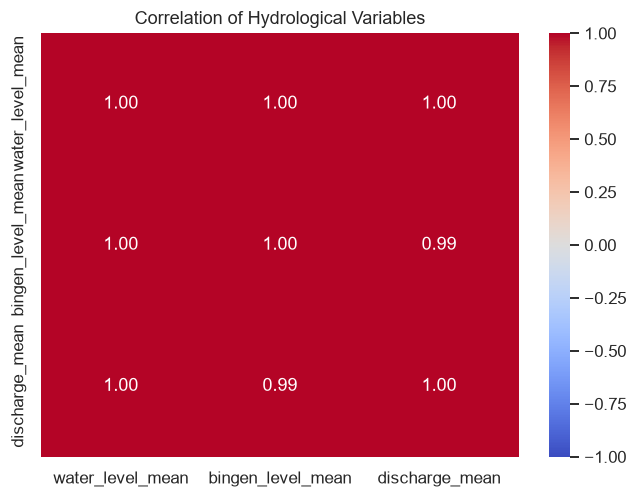

In [7]:
# Heatmap of the hydrological variables
plt.figure(figsize=(7, 5))

sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Correlation of Hydrological Variables")
plt.show()

In [8]:
# Correlation between Kaub and lagged Bingen water levels (0-7 days)
for lag in range(0, 8):
    corr = df["water_level_mean"].corr(df["bingen_level_mean"].shift(lag))
    print(f"Bingen lag {lag}: r = {corr:.3f}")

Bingen lag 0: r = 0.999
Bingen lag 1: r = 0.985
Bingen lag 2: r = 0.945
Bingen lag 3: r = 0.895
Bingen lag 4: r = 0.846
Bingen lag 5: r = 0.800
Bingen lag 6: r = 0.759
Bingen lag 7: r = 0.722


In [9]:
# Correlation between Kaub and lagged discharge (0-7 days)
for lag in range(0, 8):
    corr = df["water_level_mean"].corr(df["discharge_mean"].shift(lag))
    print(f"Discharge lag {lag}: r = {corr:.3f}")

Discharge lag 0: r = 0.995
Discharge lag 1: r = 0.977
Discharge lag 2: r = 0.934
Discharge lag 3: r = 0.881
Discharge lag 4: r = 0.829
Discharge lag 5: r = 0.782
Discharge lag 6: r = 0.740
Discharge lag 7: r = 0.702


In [10]:
# Create all features and targets with the pipeline
features = kp.make_features(df)

df = df.join(features)

print(features.columns.tolist())

['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'level_change_1d', 'level_change_3d', 'level_change_7d', 'level_change_14d', 'level_min_7d', 'level_max_7d', 'level_mean_30d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'bingen_lag_7', 'discharge_lag_1', 'discharge_lag_2', 'discharge_lag_3', 'discharge_lag_7', 'discharge_change_1d', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'precip_60d', 'precip_90d', 'temp_3d', 'temp_7d', 'snow_30d', 'et0_30d', 'doy_sin', 'doy_cos', 'target_day_1', 'target_day_2', 'target_day_3', 'target_day_4', 'target_day_5', 'target_day_6', 'target_day_7', 'target']


In [11]:
# Which rainfall window is most related to the Kaub water level?
rain_cols = [
    "precipitation_sum",
    "precip_3d",
    "precip_7d",
    "precip_14d",
    "precip_30d"
]

df[rain_cols + ["water_level_mean"]].corr()["water_level_mean"]

precipitation_sum    0.058727
precip_3d            0.178326
precip_7d            0.387781
precip_14d           0.487270
precip_30d           0.522144
water_level_mean     1.000000
Name: water_level_mean, dtype: float64

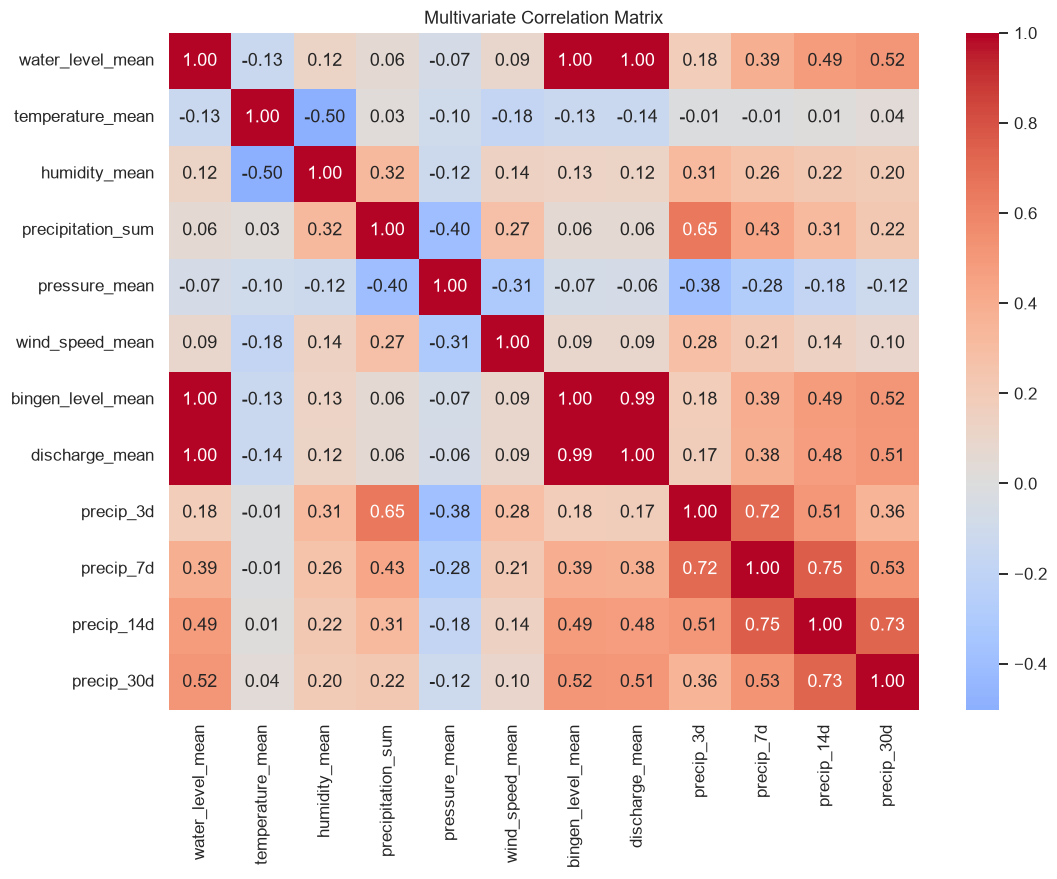

In [12]:
# Correlation matrix of hydrological and weather variables
multi_cols = [
    "water_level_mean", "temperature_mean", "humidity_mean", "precipitation_sum",
    "pressure_mean", "wind_speed_mean", "bingen_level_mean", "discharge_mean",
    "precip_3d", "precip_7d", "precip_14d", "precip_30d"
]

plt.figure(figsize=(11, 8))
sns.heatmap(df[multi_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Multivariate Correlation Matrix")
plt.show()

### Seasonal pattern across the year

Every year since 2000 on a January–December axis, with the typical range
(10th–90th percentile) and the median.

In [13]:
# Typical year: median and 10th-90th percentile for each day of the year
level = df["water_level_mean"]
doy = level.index.dayofyear

clim = level.groupby(doy).quantile([0.1, 0.5, 0.9]).unstack()
clim = clim.rolling(15, center=True, min_periods=1).mean()

last_years = sorted(level.index.year.unique())[-2:]
year_colors = {last_years[0]: "#eb6834", last_years[1]: "#1baf7a"}

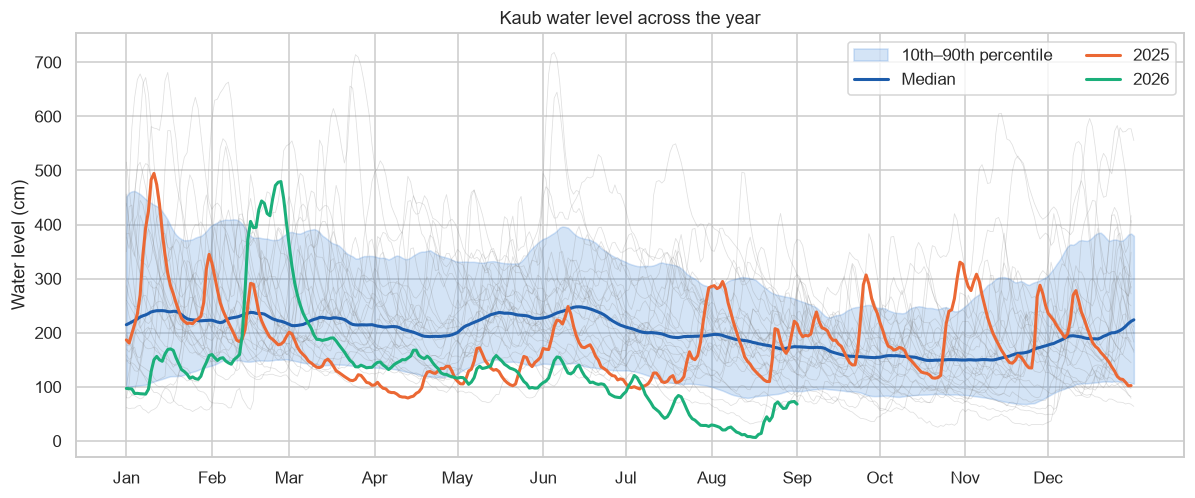

In [14]:
# Plot every year (grey) and the last two years (colour)
fig, ax = plt.subplots(figsize=(13, 5))

for year, s in level.groupby(level.index.year):
    if year not in last_years:
        ax.plot(s.index.dayofyear, s.values, color="grey", lw=0.5, alpha=0.25)

ax.fill_between(clim.index, clim[0.1], clim[0.9], color="#2a78d6", alpha=0.2,
                label="10th–90th percentile")
ax.plot(clim.index, clim[0.5], color="#1c5cab", lw=2, label="Median")

for year in last_years:
    s = level[level.index.year == year]
    ax.plot(s.index.dayofyear, s.values, color=year_colors[year], lw=2, label=str(year))

months = pd.date_range("2001-01-01", periods=12, freq="MS")
ax.set_xticks(months.dayofyear, months.strftime("%b"))
ax.set_ylabel("Water level (cm)")
ax.set_title("Kaub water level across the year")
ax.legend(ncol=2)
plt.show()

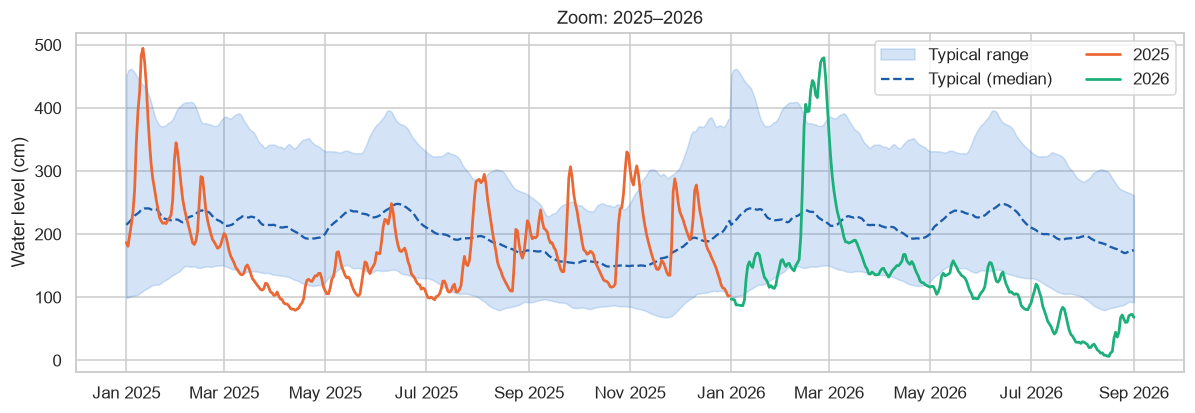

In [15]:
# Zoom: the last two years compared with the typical year
zoom = level[level.index.year >= last_years[0]].dropna()
zoom_doy = zoom.index.dayofyear

fig, ax = plt.subplots(figsize=(13, 4))

ax.fill_between(zoom.index, clim[0.1].reindex(zoom_doy), clim[0.9].reindex(zoom_doy),
                color="#2a78d6", alpha=0.2, label="Typical range")
ax.plot(zoom.index, clim[0.5].reindex(zoom_doy).to_numpy(), color="#1c5cab", ls="--",
        label="Typical (median)")

for year in last_years:
    s = zoom[zoom.index.year == year]
    ax.plot(s.index, s.values, color=year_colors[year], lw=1.8, label=str(year))

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Water level (cm)")
ax.set_title(f"Zoom: {last_years[0]}–{last_years[1]}")
ax.legend(ncol=2)
plt.show()

## 3. Features and targets

In [16]:
# Input features (all groups together) and targets 1-7 days ahead
FEATURES = kp.ALL_FEATURES
TARGETS = [f"target_day_{h}" for h in range(1, 8)]

print("FEATURES:", FEATURES)
print("TARGETS:", TARGETS)

FEATURES: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'temp_3d', 'temp_7d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'doy_sin', 'doy_cos']
TARGETS: ['target_day_1', 'target_day_2', 'target_day_3', 'target_day_4', 'target_day_5', 'target_day_6', 'target_day_7']


In [17]:
# Correlation between features and future water levels (7 horizons)
corr_horizons = df[FEATURES + TARGETS].corr().loc[FEATURES, TARGETS]

corr_horizons.round(3)

,target_day_1,target_day_2,target_day_3,target_day_4,target_day_5,target_day_6,target_day_7
lag_0,0.982,0.941,0.890,0.840,0.794,0.753,0.716
lag_1,0.941,0.890,0.840,0.794,0.753,0.716,0.684
lag_2,0.890,0.840,0.794,0.753,0.716,0.684,0.655
lag_3,0.840,0.794,0.753,0.716,0.684,0.655,0.631
lag_7,0.684,0.655,0.631,0.611,0.594,0.580,0.567
lag_14,0.555,0.544,0.533,0.523,0.514,0.505,0.494
lag_28,0.407,0.398,0.388,0.378,0.369,0.361,0.352
precip_3d,0.266,0.333,0.364,0.362,0.341,0.317,0.292
precip_7d,0.433,0.456,0.455,0.435,0.405,0.375,0.346
precip_14d,0.500,0.501,0.489,0.467,0.441,0.415,0.392


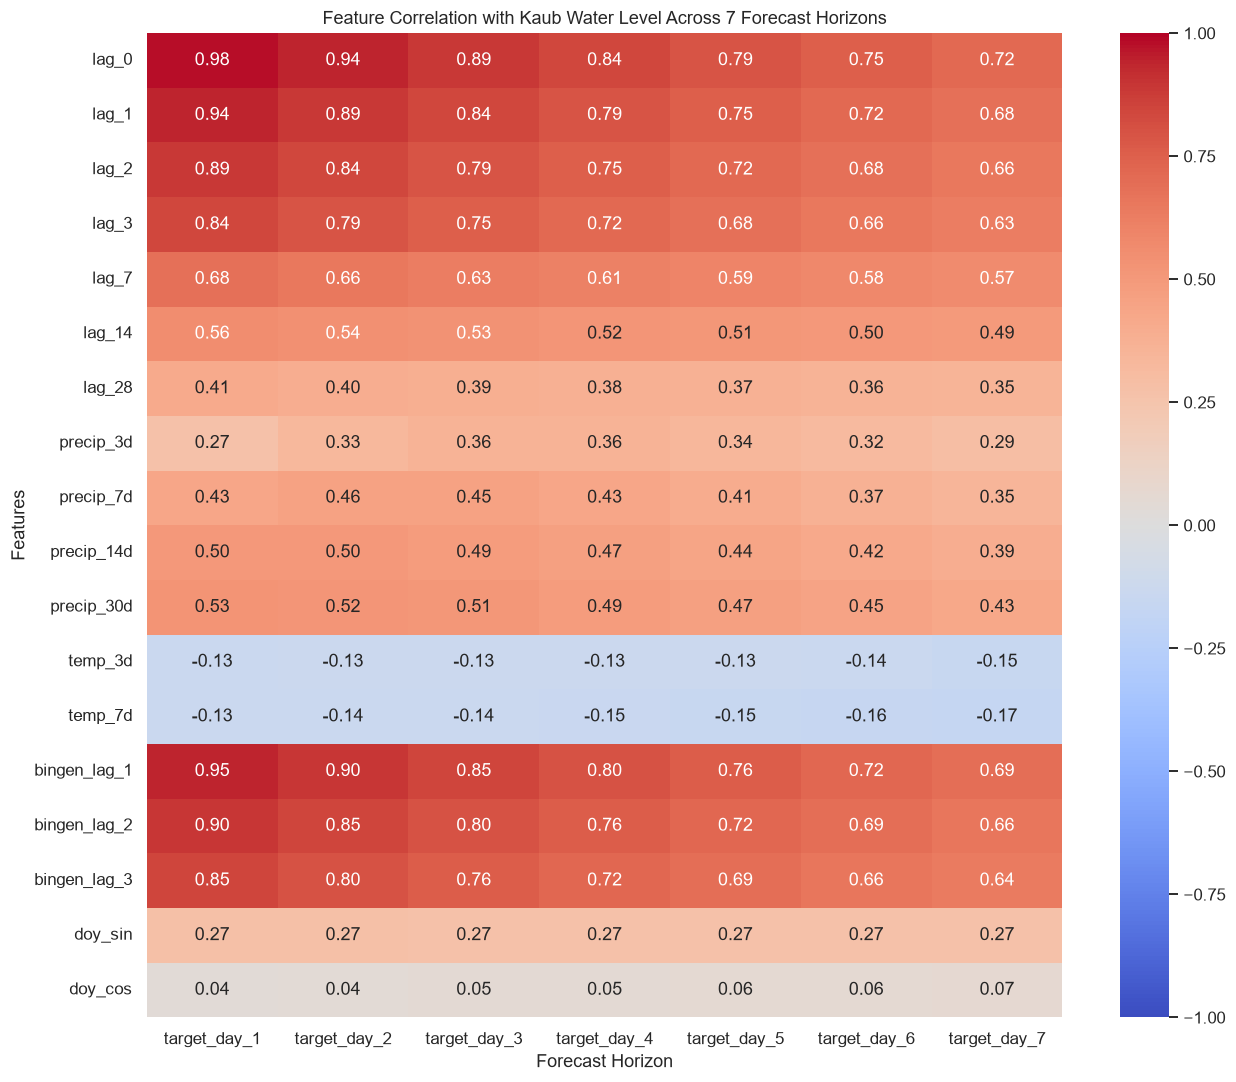

In [18]:
# Heatmap: feature correlation across the 7 forecast horizons
plt.figure(figsize=(12, 10))

sns.heatmap(corr_horizons, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1)

plt.title("Feature Correlation with Kaub Water Level Across 7 Forecast Horizons")
plt.xlabel("Forecast Horizon")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

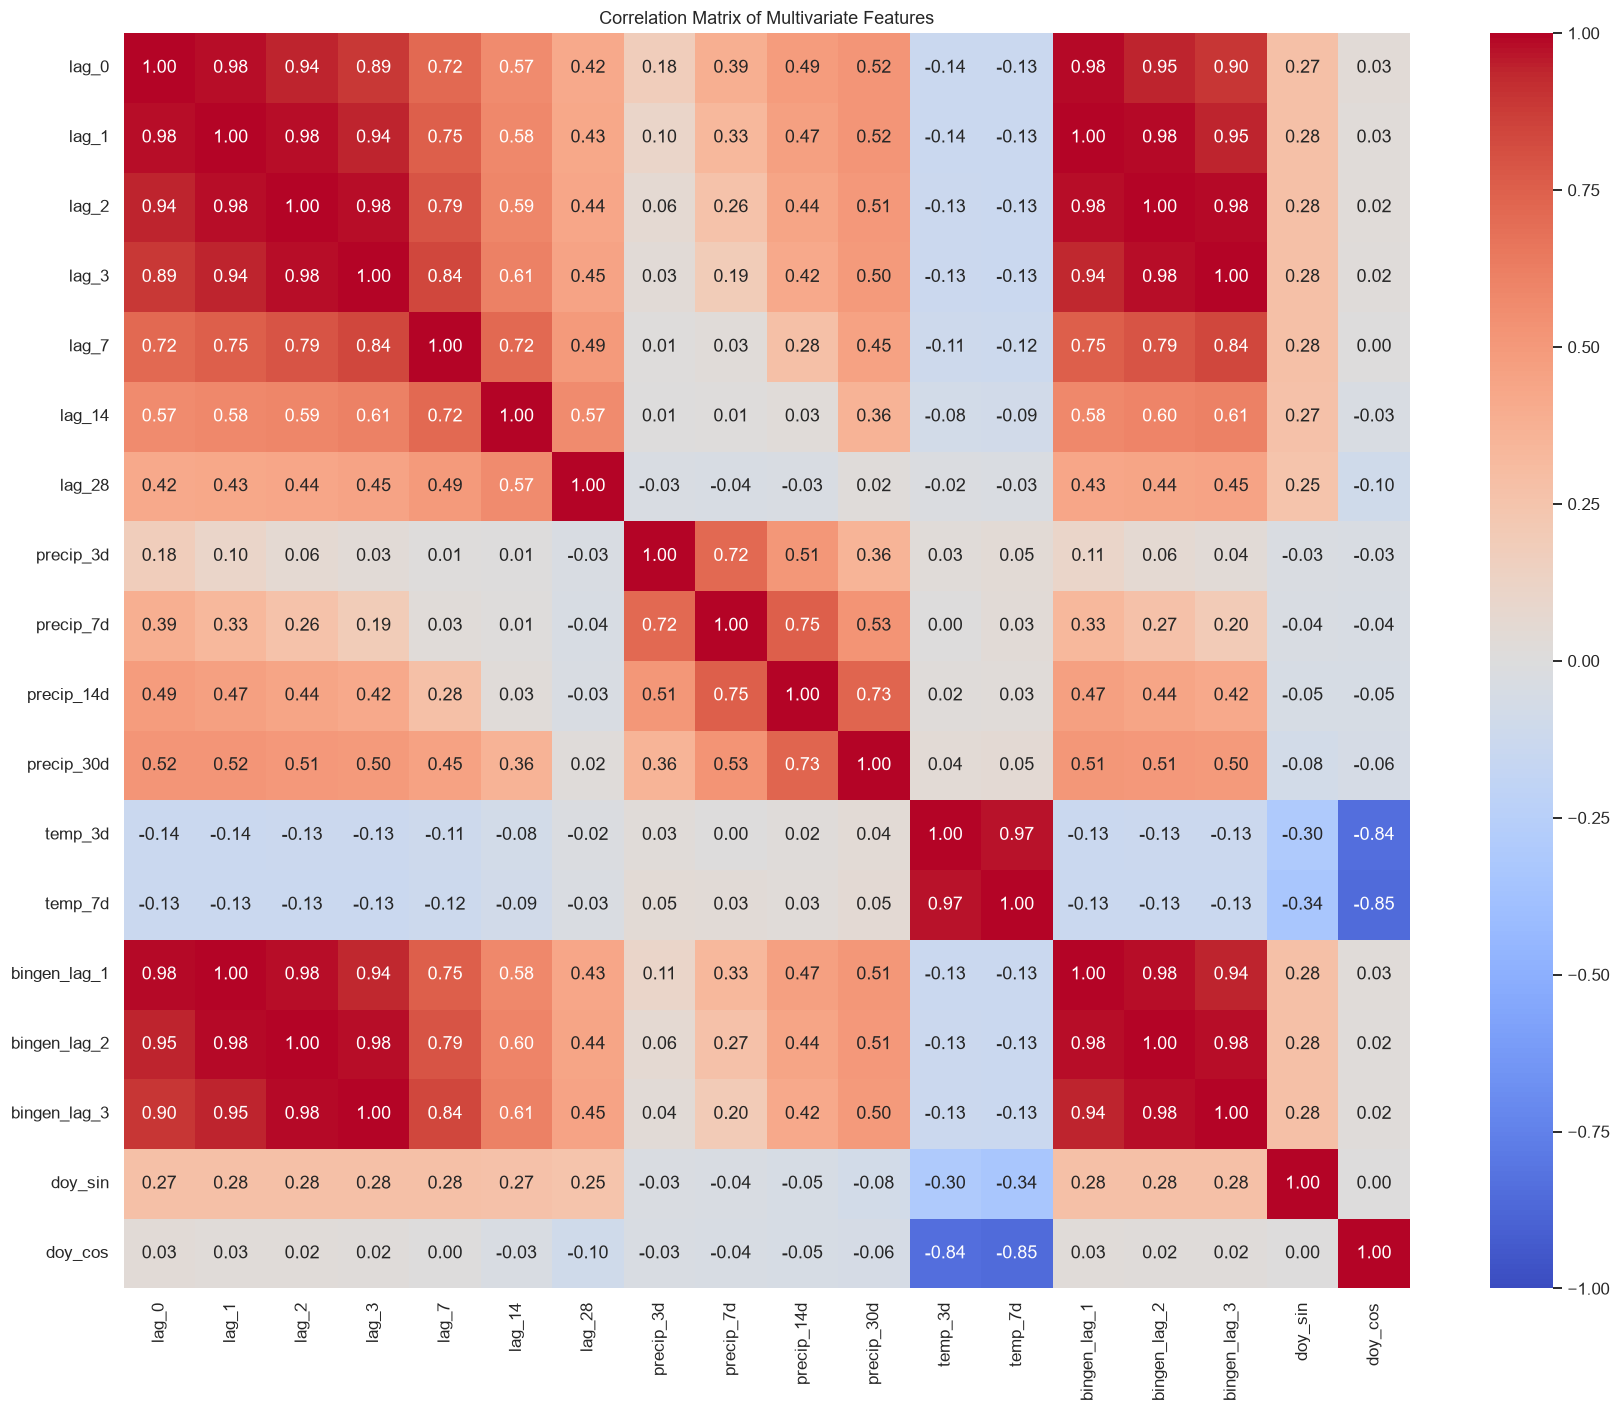

In [19]:
# Heatmap: correlation between the features
plt.figure(figsize=(16, 13))

sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1)

plt.title("Correlation Matrix of Multivariate Features")
plt.tight_layout()
plt.show()

In [20]:
# Check that features and target line up with the correct dates
day = pd.Timestamp("2010-06-15")

today = df.loc[day, "lag_0"]
in_7_days = df.loc[day + pd.Timedelta(days=H), "lag_0"]

assert df.loc[day, "target"] == in_7_days

print(f"On {day.date()}: today = {today}, target (+{H}d) = {in_7_days}")

On 2010-06-15: today = 262.0, target (+7d) = 369.0


## 4. Train / validation / test split

In [21]:
# Split by time with the pipeline: last 3 years = test, last 2 years of train = validation, 7-day gaps
splits = kp.split_data(features)

train = splits["train"]
test = splits["test"]
train_fit = splits["train_fit"]
validation = splits["validation"]

for name, part in splits.items():
    print(f"{name:10s}: {part.index.min().date()} → {part.index.max().date()} n={len(part)}")

train     : 2000-01-30 → 2023-08-25 n=8609
test      : 2023-09-02 → 2026-08-25 n=1089
train_fit : 2000-01-30 → 2021-08-18 n=7872
validation: 2021-08-26 → 2023-08-25 n=730


In [22]:
# Persistence baseline: the water level in 7 days = the water level today
y_val = validation["target"]
pred_baseline = validation["lag_0"]

persistence_mae = (pred_baseline - y_val).abs().mean()

baseline = hp.metrics(y_val, pred_baseline)
baseline["Model"] = "Persistence baseline"

pd.DataFrame([baseline]).round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Model
0,730,45.237,64.235,0.259,0.314,60.411,Persistence baseline


In [23]:
# Feature groups to compare
feature_groups = kp.FEATURE_GROUPS

for name, columns in feature_groups.items():
    print(f"{name}: {len(columns)} features")

Kaub only: 7 features
Kaub + precipitation: 11 features
Kaub + precipitation + temperature: 13 features
All selected features: 18 features


## 5. Models

In [24]:
# Linear regression for every feature group (trained by the pipeline)
lr_results_df, lr_models = kp.train_model_groups("Linear regression", splits)

lr_results_df.round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Feature group,,,,,,,,
Kaub only,730,45.446,57.376,0.409,11.681,71.781,45.237,-0.005
Kaub + precipitation,730,46.354,58.354,0.389,15.187,73.973,45.237,-0.025
Kaub + precipitation + temperature,730,45.223,56.591,0.425,15.613,73.151,45.237,0.000
All selected features,730,45.126,57.310,0.410,15.842,74.110,45.237,0.002


1. Modeling : LightGBM

In [25]:
# LightGBM for every feature group
lgbm_results_df, lgbm_models = kp.train_model_groups("LightGBM", splits)

lgbm_results_df.round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Feature group,,,,,,,,
Kaub only,730,47.013,59.391,0.367,11.176,71.644,45.237,-0.039
Kaub + precipitation,730,46.079,58.790,0.379,13.683,71.644,45.237,-0.019
Kaub + precipitation + temperature,730,44.668,56.900,0.419,13.848,72.192,45.237,0.013
All selected features,730,44.847,57.250,0.412,15.602,72.192,45.237,0.009


2. Random Forest :

In [26]:
# Random forest for every feature group
rf_results_df, rf_models = kp.train_model_groups("Random forest", splits)

rf_results_df.round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Feature group,,,,,,,,
Kaub only,730,46.583,59.901,0.356,9.917,68.904,45.237,-0.030
Kaub + precipitation,730,47.081,60.650,0.340,14.245,71.918,45.237,-0.041
Kaub + precipitation + temperature,730,45.223,57.510,0.406,14.469,71.233,45.237,0.000
All selected features,730,46.916,59.301,0.369,16.829,72.055,45.237,-0.037


In [27]:
# Best random forest
best_rf_group = rf_results_df["MAE"].idxmin()

print("Best feature group:", best_rf_group)
print(f"Validation MAE: {rf_results_df.loc[best_rf_group, 'MAE']:.3f} cm")

Best feature group: Kaub + precipitation + temperature
Validation MAE: 45.223 cm


3. Modeling : XGBoost

In [28]:
# XGBoost for every feature group
xgb_results_df, xgb_models = kp.train_model_groups("XGBoost", splits)

xgb_results_df.round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Feature group,,,,,,,,
Kaub only,730,46.344,59.724,0.360,10.303,70.137,45.237,-0.024
Kaub + precipitation,730,45.384,59.683,0.360,11.580,70.000,45.237,-0.003
Kaub + precipitation + temperature,730,43.475,56.325,0.430,11.930,69.589,45.237,0.039
All selected features,730,44.410,56.811,0.421,15.317,70.137,45.237,0.018


In [29]:
# Best XGBoost: train again on all training years, then predict the test years once
best_group = xgb_results_df["MAE"].idxmin()

final_xgb, test_predictions = kp.refit_and_test("XGBoost", best_group, splits)

print("Best feature group:", best_group)

Best feature group: Kaub + precipitation + temperature


In [30]:
# Test results
y_test = test["target"]

test_result = hp.metrics(y_test, test_predictions, test["lag_0"])
test_result["Model"] = "XGBoost"

pd.DataFrame([test_result]).round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence,Model
0,1089,47.187,63.829,0.676,-0.386,60.514,50.816,0.071,XGBoost


In [31]:
# Error table for the test data
errors = pd.DataFrame({
    "Actual": y_test,
    "Predicted": test_predictions,
    "Persistence": test["lag_0"]
})

# Positive error = overprediction
errors["Error"] = errors["Predicted"] - errors["Actual"]
errors["Absolute error"] = errors["Error"].abs()

errors.head()

,Actual,Predicted,Persistence,Error,Absolute error
date,,,,,
2023-09-02,161.0,242.949966,274.0,81.949966,81.949966
2023-09-03,157.0,208.131119,249.0,51.131119,51.131119
2023-09-04,151.0,185.723267,227.0,34.723267,34.723267
2023-09-05,146.0,184.937057,205.0,38.937057,38.937057
2023-09-06,147.0,198.275040,188.0,51.275040,51.275040


In [32]:
# Error by water condition (low / normal / high), based on the actual level
high_threshold = train["target"].quantile(0.90)

error_summary = hp.regime_table(
    errors["Actual"], errors["Predicted"], errors["Persistence"],
    low_cm=LOW_WATER_THRESHOLD, high_cm=high_threshold
)

print(f"Low water < {LOW_WATER_THRESHOLD} cm, high water >= {high_threshold:.0f} cm")
error_summary.round(2)

Low water < 77 cm, high water >= 343 cm


,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Condition,,,,,,,,
All levels,1089,47.19,63.83,0.68,-0.39,60.51,50.82,0.07
Low water,55,35.86,42.49,-2.68,35.27,94.55,23.58,-0.52
Normal water,882,39.44,48.95,0.47,11.19,65.76,43.81,0.10
High water,152,96.21,120.95,-1.99,-80.44,17.76,101.34,0.05


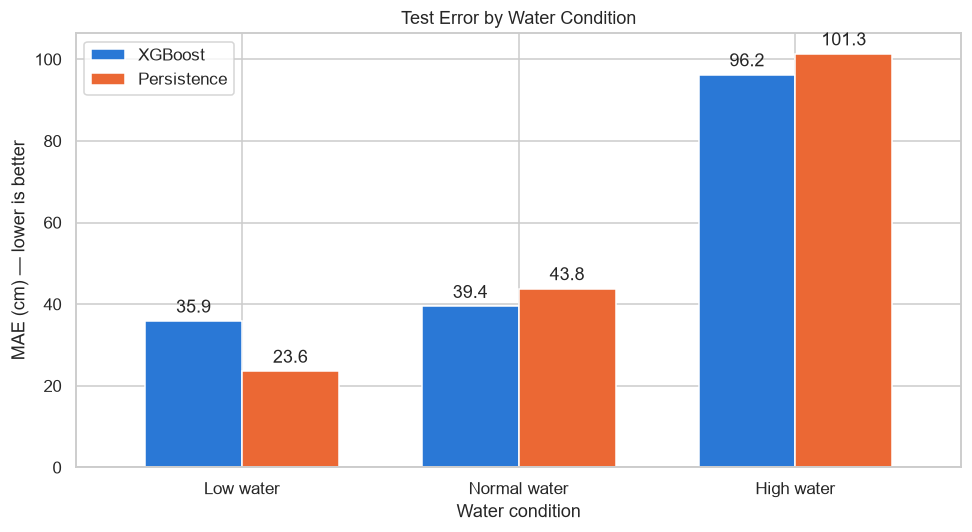

In [33]:
# Bar chart: XGBoost vs persistence per water condition
plot_data = error_summary.loc[["Low water", "Normal water", "High water"],
                              ["MAE", "Persistence MAE"]]
plot_data.columns = ["XGBoost", "Persistence"]

ax = plot_data.plot.bar(figsize=(9, 5), color=["#2a78d6", "#eb6834"], rot=0, width=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.set(title="Test Error by Water Condition", xlabel="Water condition",
       ylabel="MAE (cm) — lower is better")
plt.tight_layout()
plt.show()

In [34]:
# Low-water alarm: will Kaub be below the threshold in 7 days? (watch Recall: missed alarms are costly)
pd.DataFrame({
    "XGBoost": hp.alarm_scores(y_test, test_predictions),
    "Persistence": hp.alarm_scores(y_test, test["lag_0"]),
}).T.round(3)

,Low-water days,Hits,Missed alarms,False alarms,Recall,Precision
XGBoost,55.0,31.0,24.0,3.0,0.564,0.912
Persistence,55.0,41.0,14.0,7.0,0.745,0.854


In [35]:
# The 10 biggest test errors
errors["Target date"] = (errors.index + pd.Timedelta(days=H)).date

errors.nlargest(10, "Absolute error")[
    ["Target date", "Actual", "Predicted", "Error", "Absolute error"]
].round(2)

,Target date,Actual,Predicted,Error,Absolute error
date,,,,,
2023-11-12,2023-11-19,520.0,220.759995,-299.24,299.24
2024-05-29,2024-06-05,645.0,366.959991,-278.04,278.04
2024-05-28,2024-06-04,634.0,366.850006,-267.15,267.15
2023-12-08,2023-12-15,581.0,315.329987,-265.67,265.67
2023-11-13,2023-11-20,527.0,263.899994,-263.10,263.10
2023-11-11,2023-11-18,499.0,243.509995,-255.49,255.49
2026-02-08,2026-02-15,406.0,177.770004,-228.23,228.23
2025-01-01,2025-01-08,395.0,168.190002,-226.81,226.81
2023-11-10,2023-11-17,452.0,225.330002,-226.67,226.67


In [36]:
# Over-fitting check: training vs validation error
group = "Kaub + precipitation + temperature"
model = xgb_models[group]
columns = feature_groups[group]

comparison = []

for name, subset in [("Training", train_fit), ("Validation", validation)]:
    row = hp.metrics(subset["target"], model.predict(subset[columns]))
    row["Dataset"] = name
    comparison.append(row)

pd.DataFrame(comparison).set_index("Dataset").round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%)
Dataset,,,,,,
Training,7872,36.607,50.332,0.748,0.004,60.226
Validation,730,43.475,56.325,0.430,11.930,69.589


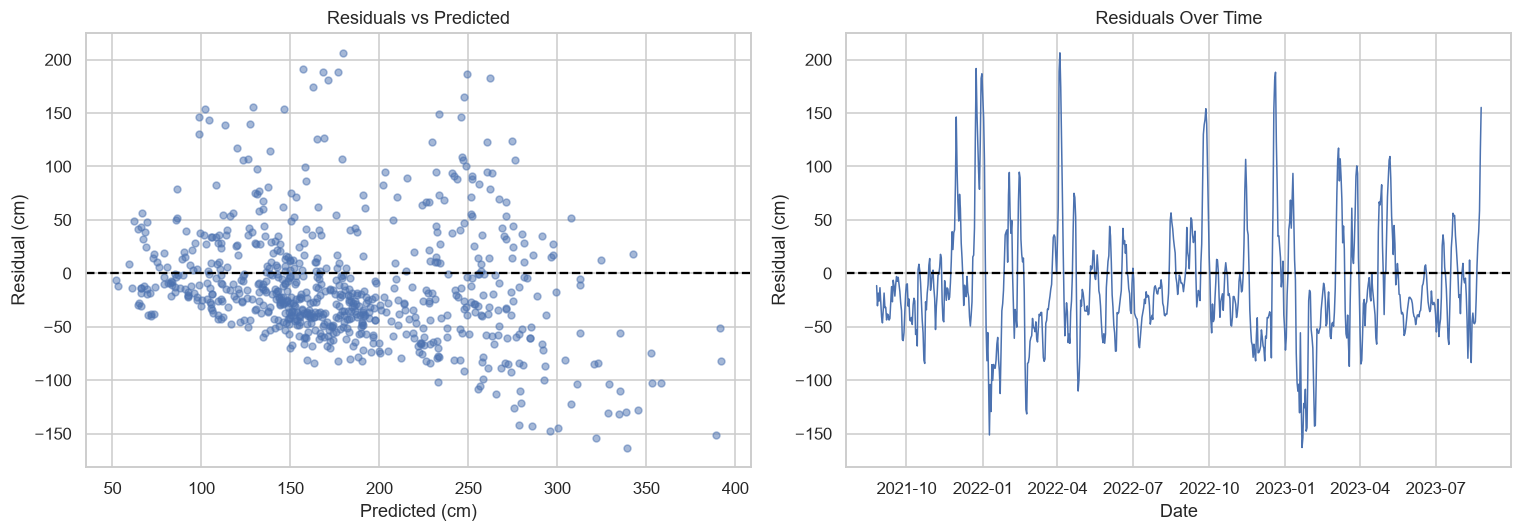

In [37]:
# Residual analysis on the validation data
best_model = xgb_models[best_group]
best_columns = feature_groups[best_group]

y_pred = best_model.predict(validation[best_columns])
residuals = y_val.to_numpy() - y_pred   # actual − predicted

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred, residuals, alpha=0.5, s=20)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(title="Residuals vs Predicted", xlabel="Predicted (cm)", ylabel="Residual (cm)")

axes[1].plot(validation.index, residuals, linewidth=1)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(title="Residuals Over Time", xlabel="Date", ylabel="Residual (cm)")

plt.tight_layout()
plt.show()

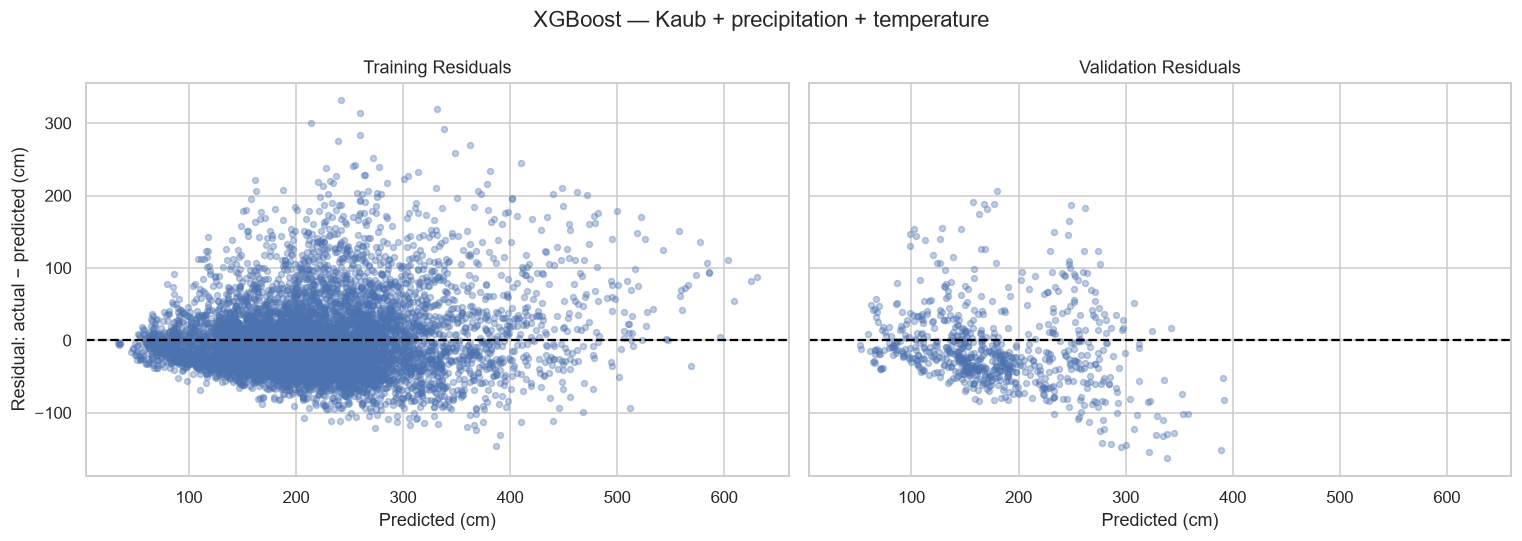

In [38]:
# Residuals: training vs validation
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, (name, subset) in zip(axes, [("Training", train_fit), ("Validation", validation)]):
    predictions = best_model.predict(subset[best_columns])
    residuals = subset["target"].to_numpy() - predictions

    ax.scatter(predictions, residuals, alpha=0.35, s=15)
    ax.axhline(0, color="black", linestyle="--")
    ax.set(title=f"{name} Residuals", xlabel="Predicted (cm)")

axes[0].set_ylabel("Residual: actual − predicted (cm)")
fig.suptitle(f"XGBoost — {best_group}")
plt.tight_layout()
plt.show()

In [39]:
# Validation error by condition (thresholds = 10th and 90th percentile of training)
low_q = train_fit["target"].quantile(0.10)
high_q = train_fit["target"].quantile(0.90)

extreme_results = hp.regime_table(
    y_val, best_model.predict(validation[best_columns]), pred_baseline,
    low_cm=low_q, high_cm=high_q
)

print(f"Low < {low_q:.0f} cm, high >= {high_q:.0f} cm")
extreme_results.round(2)

Low < 110 cm, high >= 349 cm


,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Condition,,,,,,,,
All levels,730,43.47,56.33,0.43,11.93,69.59,45.24,0.04
Low water,149,31.20,37.54,-2.60,27.05,87.92,19.56,-0.59
Normal water,560,43.31,54.66,0.13,13.42,67.32,48.16,0.10
High water,21,134.97,143.58,-26.13,-134.97,0.00,149.33,0.10


Polynomial Features

In [40]:
# Polynomial features (degree 2) + Ridge regression for every feature group
poly_results_df, poly_models = kp.train_model_groups("Polynomial ridge", splits)

poly_results_df.round(3)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Feature group,,,,,,,,
Kaub only,730,45.063,57.604,0.404,10.342,70.548,45.237,0.004
Kaub + precipitation,730,45.562,59.313,0.368,12.193,71.096,45.237,-0.007
Kaub + precipitation + temperature,730,43.102,56.022,0.437,11.261,66.712,45.237,0.047
All selected features,730,43.711,56.566,0.426,13.257,69.178,45.237,0.034


In [41]:
# How many columns do the polynomial features create?
for group, model in poly_models.items():
    poly = model.named_steps["polynomialfeatures"]
    print(f"{group}: {len(feature_groups[group])} original → {poly.n_output_features_} polynomial features")

Kaub only: 7 original → 35 polynomial features
Kaub + precipitation: 11 original → 77 polynomial features
Kaub + precipitation + temperature: 13 original → 104 polynomial features
All selected features: 18 original → 189 polynomial features


In [42]:
# Compare all models on the validation data
all_results = []

for model_name, results in [("Linear regression", lr_results_df),
                            ("LightGBM", lgbm_results_df),
                            ("Random Forest", rf_results_df),
                            ("XGBoost", xgb_results_df),
                            ("Polynomial Ridge", poly_results_df)]:
    table = results[["MAE", "RMSE", "Bias", "Skill vs persistence"]].reset_index()
    table["Model"] = model_name
    all_results.append(table)

model_comparison = pd.concat(all_results).sort_values("MAE").reset_index(drop=True)

print(f"Persistence validation MAE: {persistence_mae:.3f} cm")
model_comparison.round(3)

Persistence validation MAE: 45.237 cm


,Feature group,MAE,RMSE,Bias,Skill vs persistence,Model
0,Kaub + precipitation + temperature,43.102,56.022,11.261,0.047,Polynomial Ridge
1,Kaub + precipitation + temperature,43.475,56.325,11.930,0.039,XGBoost
2,All selected features,43.711,56.566,13.257,0.034,Polynomial Ridge
3,All selected features,44.410,56.811,15.317,0.018,XGBoost
4,Kaub + precipitation + temperature,44.668,56.900,13.848,0.013,LightGBM
5,All selected features,44.847,57.250,15.602,0.009,LightGBM
6,Kaub only,45.063,57.604,10.342,0.004,Polynomial Ridge
7,All selected features,45.126,57.310,15.842,0.002,Linear regression
8,Kaub + precipitation + temperature,45.223,57.510,14.469,0.000,Random Forest
9,Kaub + precipitation + temperature,45.223,56.591,15.613,0.000,Linear regression


In [43]:
# Best model overall
best_result = model_comparison.iloc[0]

print("Best model:", best_result["Model"])
print("Best feature group:", best_result["Feature group"])
print(f"Validation MAE: {best_result['MAE']:.3f} cm")

Best model: Polynomial Ridge
Best feature group: Kaub + precipitation + temperature
Validation MAE: 43.102 cm


# Error Analysis :

In [44]:
# Low-water errors for the chosen model (training vs validation)
group = "Kaub + precipitation + temperature"
model = xgb_models[group]
columns = feature_groups[group]

tables = []

for name, subset in [("Training", train_fit), ("Validation", validation)]:
    table = hp.regime_table(subset["target"], model.predict(subset[columns]), subset["lag_0"])
    table["Dataset"] = name
    tables.append(table)

pd.concat(tables).round(2)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence,Dataset
Condition,,,,,,,,,
All levels,7872,36.61,50.33,0.75,0.00,60.23,52.96,0.31,Training
Low water,290,20.77,24.56,-2.47,19.63,89.66,12.73,-0.63,Training
Other levels,7582,37.21,51.06,0.72,-0.75,59.10,54.50,0.32,Training
All levels,730,43.47,56.33,0.43,11.93,69.59,45.24,0.04,Validation
Low water,50,24.06,27.62,-2.59,23.72,98.00,14.62,-0.65,Validation
Other levels,680,44.90,57.88,0.34,11.06,67.50,47.49,0.05,Validation


In [45]:
# Validation error table
val_errors = pd.DataFrame({
    "Actual": y_val,
    "Predicted": model.predict(validation[columns]),
    "Persistence": pred_baseline
})

val_errors["Target date"] = (val_errors.index + pd.Timedelta(days=H)).date
val_errors["Error"] = val_errors["Predicted"] - val_errors["Actual"]

val_errors.head().round(2)

,Actual,Predicted,Persistence,Target date,Error
date,,,,,
2021-08-26,240.0,251.539993,237.0,2021-09-02,11.54
2021-08-27,225.0,255.410004,220.0,2021-09-03,30.41
2021-08-28,211.0,229.570007,212.0,2021-09-04,18.57
2021-08-29,202.0,228.000000,208.0,2021-09-05,26.00
2021-08-30,195.0,208.490005,212.0,2021-09-06,13.49


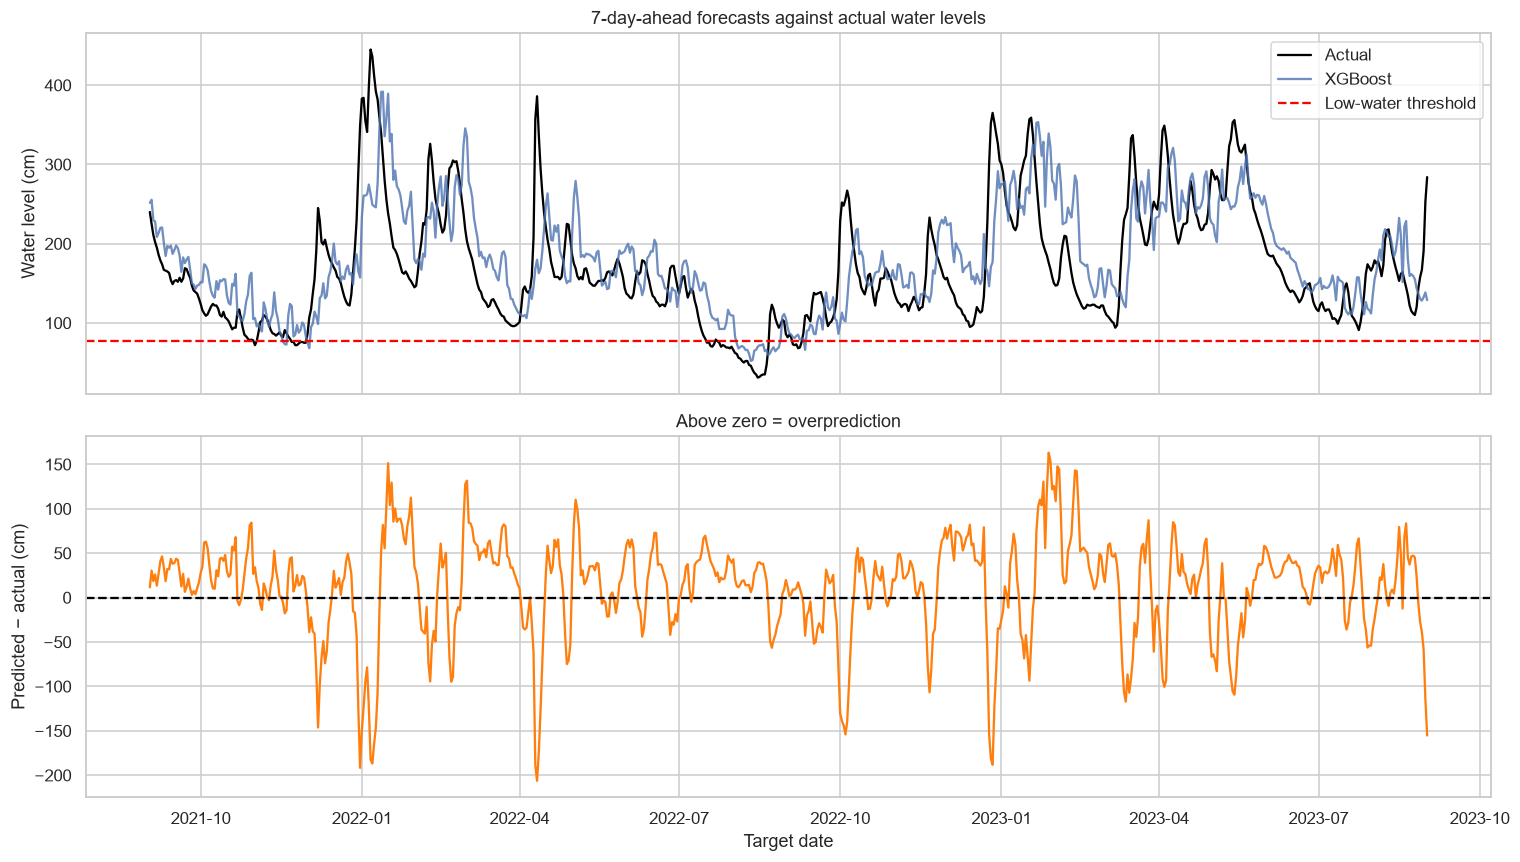

In [46]:
# Forecasts vs actual levels, and the error over time
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(val_errors["Target date"], val_errors["Actual"], label="Actual", color="black")
axes[0].plot(val_errors["Target date"], val_errors["Predicted"], label="XGBoost", alpha=0.8)
axes[0].axhline(LOW_WATER_THRESHOLD, color="red", linestyle="--", label="Low-water threshold")
axes[0].set(ylabel="Water level (cm)", title="7-day-ahead forecasts against actual water levels")
axes[0].legend()

axes[1].plot(val_errors["Target date"], val_errors["Error"], color="tab:orange")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(ylabel="Predicted − actual (cm)", xlabel="Target date",
            title="Above zero = overprediction")

plt.tight_layout()
plt.show()

In [47]:
# Worst low-water overpredictions (model promised more water than there was)
low_and_over = (val_errors["Actual"] < LOW_WATER_THRESHOLD) & (val_errors["Error"] > 0)

val_errors[low_and_over].nlargest(10, "Error").round(2)

,Actual,Predicted,Persistence,Target date,Error
date,,,,,
2022-07-10,75.0,134.389999,128.0,2022-07-17,59.39
2022-07-11,76.0,126.290001,120.0,2022-07-18,50.29
2022-07-22,69.0,116.599998,79.0,2022-07-29,47.60
2021-11-15,76.0,121.410004,88.0,2021-11-22,45.41
2022-07-25,66.0,109.180000,70.0,2022-08-01,43.18
2022-07-23,68.0,110.779999,77.0,2022-07-30,42.78
2022-07-12,71.0,112.080002,108.0,2022-07-19,41.08
2022-08-09,32.0,71.820000,52.0,2022-08-16,39.82
2022-07-24,70.0,109.389999,75.0,2022-07-31,39.39


Save Model for streamlit

In [48]:
# Save the model with the pipeline (same format the Streamlit app reads)
save_group = "Kaub + precipitation + temperature"

kp.save_model(xgb_models[save_group], features=feature_groups[save_group])

print("Saved to", kp.MODEL_PATH)

Saved to C:\Users\Prithvi Hegde\neuefische_course\Rhine-cargo-advisor\models\kaub_xgboost_04.joblib


In [49]:
# Load the saved model and use it: forecast for the latest days in the data
saved = kp.load_model()

forecast = kp.predict(saved, kp.load_data())

forecast.tail()

,today_level,forecast_date,forecast_level,low_water_alarm
date,,,,
2026-08-28,61.0,2026-09-04,70.918182,True
2026-08-29,70.0,2026-09-05,71.013962,True
2026-08-30,72.0,2026-09-06,73.205002,True
2026-08-31,73.0,2026-09-07,63.938938,True
2026-09-01,68.0,2026-09-08,62.468143,True
